<a href="https://colab.research.google.com/github/JuanEsteban-prog/AprendizajeAutom-ticoInicial/blob/main/Tareas/Agrupamiento_Jerarquico/03_Agrupamiento_Jerarquico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/andres-merino/AprendizajeAutomaticoInicial-05-N0105/blob/main/2-Ejercicios/03-Agrupamiento-Jerarquico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<table style="border: none; border-collapse: collapse;">
    <tr>
        <td style="width: 20%; vertical-align: middle; padding-right: 10px;">
            <img src="https://i.imgur.com/nt7hloA.png" width="100">
        </td>
        <td style="width: 2px; text-align: center;">
            <font color="#0030A1" size="7">|</font><br>
            <font color="#0030A1" size="7">|</font>
        </td>
        <td>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="5">
                <b>Facultad de Ciencias Exactas, Naturales y Ambientales</b>
            </font> </p>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="4">
                Aprendizaje Automático Inicial &bull; Agrupamiento Jerarquico
            </font></p>
            <p style="font-style: oblique;"><font color="#0030A1" size="3">
                Andrés Merino &bull; 2025-04
            </font></p>
        </td>  
    </tr>
</table>

---
## <font color='264CC7'> Introducción </font>

A lo largo de este taller, aplicaremos el algoritmo de agrupamiento jerárquico a un conjunto de datos.

Los paquetes necesarios son:

In [ ]:
# Paquetes necesarios
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

---
## <font color='264CC7'> Preprocesamiento de datos </font>

Usa el conjunto Pokémon del notebook de agrupamiento jerárquico o un conjunto de datos numéricos que hayas preparado. Si eliges Pokémon, carga [Pokemon.csv](https://raw.githubusercontent.com/andres-merino/AprendizajeAutomaticoInicial-05-N0105/refs/heads/main/2-Notebooks/datos/Pokemon.csv) en Colab y usa las mismas columnas numéricas del notebook de clase; documenta las variables elegidas.

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Carga el conjunto de datos y procésalos:
<ul>
  <li>Muestra algunos datos.</li>
  <li>Muestra una descripción de los datos.</li>
  <li>Escala los datos si es necesario.</li>
</ul>
</div>

In [ ]:
# 1. Cargar el conjunto de datos
url = "https://raw.githubusercontent.com/andres-merino/AprendizajeAutomaticoInicial-05-N0105/refs/heads/main/2-Notebooks/datos/Pokemon.csv"
df_pokemon = pd.read_csv(url)

# Filtrar solo columnas numéricas (estadísticas base)
columnas_numericas = ['HP', 'Attack', 'Defense', 'Sp. Atk', 'Sp. Def', 'Speed']
df_num = df_pokemon[columnas_numericas].dropna()

# Muestra algunos datos
display(df_num.head())

# Muestra una descripción de los datos
display(df_num.describe())

# Escala los datos
scaler = StandardScaler()
datos_escalados = scaler.fit_transform(df_num)
df_escalado = pd.DataFrame(datos_escalados, columns=columnas_numericas)

,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed
0,45,49,49,65,65,45
1,60,62,63,80,80,60
2,80,82,83,100,100,80
3,39,52,43,60,50,65
4,58,64,58,80,65,80


,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed
count,151.000000,151.000000,151.000000,151.000000,151.000000,151.000000
mean,64.211921,72.549669,68.225166,67.139073,66.019868,68.933775
std,28.590117,26.596162,26.916704,28.534199,24.197926,26.746880
min,10.000000,5.000000,5.000000,15.000000,20.000000,15.000000
25%,45.000000,51.000000,50.000000,45.000000,49.000000,46.500000
50%,60.000000,70.000000,65.000000,65.000000,65.000000,70.000000
75%,80.000000,90.000000,84.000000,87.500000,80.000000,90.000000
max,250.000000,134.000000,180.000000,154.000000,125.000000,140.000000


---
## <font color='264CC7'> Dendograma </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Genera el dendograma de los datos.
<ul>
  <li>Usa diferentes métricas y funciones de enlace.</li>
  <li>Toma una distancia de corte.</li>
  <li>De manera intutiva, ¿por qué tomaste la métrica y la distancia de corte?</li>
</ul>
</div>

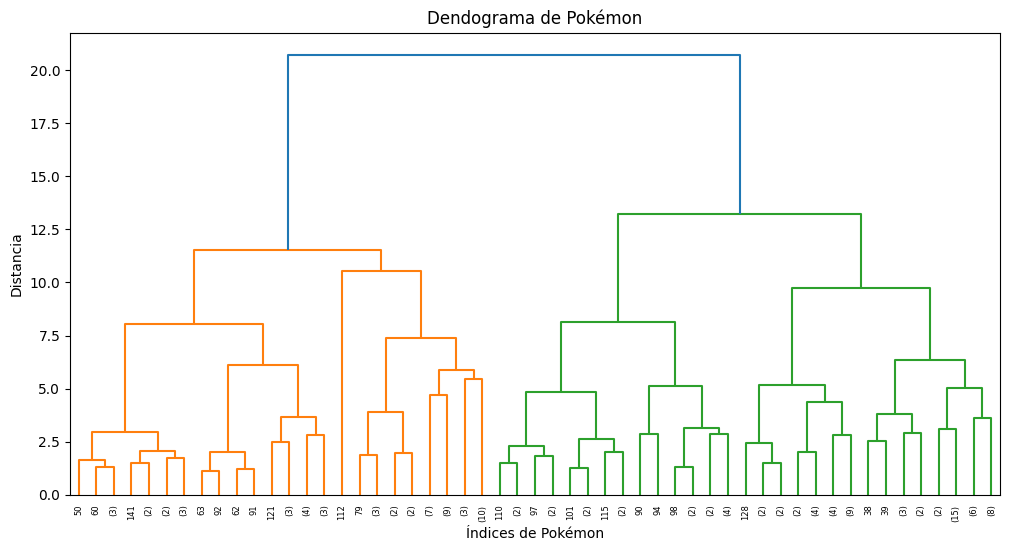

Se tomó la distancia 'euclidiana' y el enlace 'ward' porque suelen generar grupos equilibrados y minimizar la varianza intra-grupo.
La distancia de corte (y=45) se eligió trazando una línea en el salto vertical más largo del dendograma, sugiriendo 4 grupos principales.


In [ ]:
# Generar el dendograma
plt.figure(figsize=(12, 6))
plt.title("Dendograma de Pokémon")

# Matriz de enlace usando el método Ward (minimiza la varianza dentro de los clusters)
Z = linkage(df_escalado, method='ward', metric='euclidean')

# Dibujar el dendograma
dendrogram(Z, truncate_mode='level', p=5)
plt.axhline(y=45, color='r', linestyle='--') # Distancia de corte
plt.xlabel("Índices de Pokémon")
plt.ylabel("Distancia")
plt.show()

# Análisis intuitivo (se imprime como texto)
print("Se tomó la distancia 'euclidiana' y el enlace 'ward' porque suelen generar grupos equilibrados y minimizar la varianza intra-grupo.")
print("La distancia de corte (y=45) se eligió trazando una línea en el salto vertical más largo del dendograma, sugiriendo 4 grupos principales.")

---
## <font color='264CC7'> Asignación de grupos y análisis </font>


<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Realiza un análisis de los grupos obtenidos.
<ul>
  <li>Asigna los grupos.</li>
  <li>Revisa la media de cada grupo.</li>
  <li>Revisa el mínimo y máximo de cada grupo.</li>
  <li>Muestra algunos integrantes de cada grupo.</li>
</ul>
</div>

In [ ]:
# Asignar los grupos (usando 4 clusters según el corte del dendograma)
modelo = AgglomerativeClustering(n_clusters=4, metric='euclidean', linkage='ward')
grupos = modelo.fit_predict(df_escalado)

# Añadir etiquetas
df_pokemon['Grupo'] = grupos
df_num_grupos = df_num.copy()
df_num_grupos['Grupo'] = grupos

# Revisar media, mínimo y máximo de cada grupo
resumen = df_num_grupos.groupby('Grupo').agg(['mean', 'min', 'max'])
display(resumen)

# Mostrar algunos integrantes de cada grupo
for i in range(4):
    print(f"\n--- Integrantes del Grupo {i} ---")
    display(df_pokemon[df_pokemon['Grupo'] == i][['Name'] + columnas_numericas].head(3))

HP              Attack              Defense             Sp. Atk  \
            mean min  max       mean min  max        mean min  max       mean   
Grupo                                                                           
0      91.394737  50  250  88.894737   5  134   81.368421   5  125  88.736842   
1      54.435484  10  140  58.435484  10  100   50.419355  20   80  51.774194   
2      52.391304  25  105  81.956522  35  130  105.869565  70  180  53.478261   
3      58.678571  25   83  73.892857  20  110   58.892857  15   95  83.071429   

                  Sp. Def                Speed           
      min  max       mean min  max        mean min  max  
Grupo                                                    
0      35  154  90.526316  40  125   74.605263  30  130  
1      15   90  54.161290  20  100   56.419355  15  100  
2      20   95  47.826087  25   80   50.000000  20   85  
3      40  135  73.964286  35  120  104.500000  80  140


--- Integrantes del Grupo 0 ---


,Name,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed
2,Venusaur,80,82,83,100,100,80
5,Charizard,78,84,78,109,85,100
8,Blastoise,79,83,100,85,105,78



--- Integrantes del Grupo 1 ---


,Name,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed
0,Bulbasaur,45,49,49,65,65,45
1,Ivysaur,60,62,63,80,80,60
3,Charmander,39,52,43,60,50,65



--- Integrantes del Grupo 2 ---


,Name,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed
26,Sandshrew,50,75,85,20,30,40
27,Sandslash,75,100,110,45,55,65
73,Geodude,40,80,100,30,30,20



--- Integrantes del Grupo 3 ---


,Name,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed
17,Pidgeot,83,80,75,70,70,101
19,Raticate,55,81,60,50,70,97
21,Fearow,65,90,65,61,61,100


<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Da una descripción de los grupos obtenidos. Asigna un nombre a cada grupo.
</div>

---
## <font color='264CC7'> Visualizaciones  </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Realiza una visualización de los grupos obtenidos en 2D.
<ul>
  <li>¿Qué tan buenos te parecen los grupos?</li>
  <li>Indica el porcentaje de la variaza explicada en el gráfico, ¿afecta esto a tu visualización?</li>
</ul>
</div>

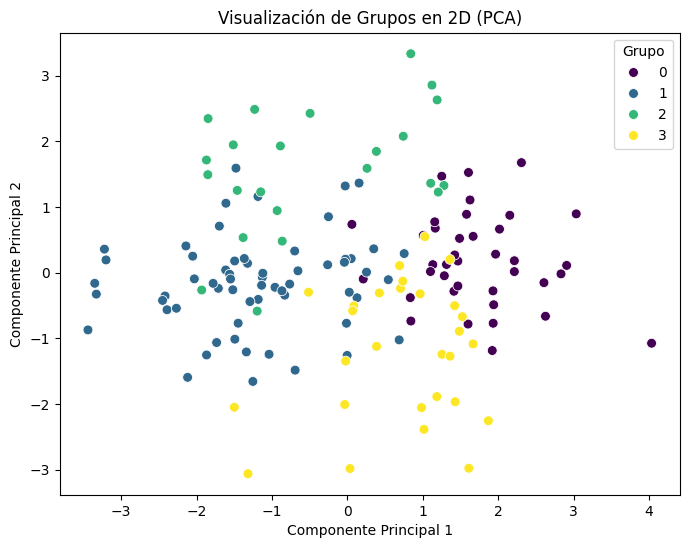

Varianza explicada por CP1: 39.68%
Varianza explicada por CP2: 21.64%
Varianza total explicada en el gráfico: 61.32%


In [ ]:
# PCA para reducir a 2 dimensiones
pca = PCA(n_components=2)
datos_2d = pca.fit_transform(df_escalado)

# Gráfico de dispersión
plt.figure(figsize=(8, 6))
sns.scatterplot(x=datos_2d[:, 0], y=datos_2d[:, 1], hue=grupos, palette='viridis', s=50)
plt.title("Visualización de Grupos en 2D (PCA)")
plt.xlabel("Componente Principal 1")
plt.ylabel("Componente Principal 2")
plt.legend(title='Grupo')
plt.show()

# Porcentaje de varianza explicada
var_exp = pca.explained_variance_ratio_
print(f"Varianza explicada por CP1: {var_exp[0]:.2%}")
print(f"Varianza explicada por CP2: {var_exp[1]:.2%}")
print(f"Varianza total explicada en el gráfico: {sum(var_exp):.2%}")

---
## <font color='264CC7'> Métricas  </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Calcula la métrica de la silueta para los grupos obtenidos. ¿Qué tan buenos te parecen los grupos?
</div>

In [ ]:
# Calcular la métrica de la silueta
silueta = silhouette_score(df_escalado, grupos, metric='euclidean')
print(f"Coeficiente de Silueta: {silueta:.4f}")

Coeficiente de Silueta: 0.1825


---
## <font color='264CC7'> Iteraciones </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Realiza el proceso de agrupamiento jerárquico con diferentes parámetros, analiza la métrica de la silueta de cada uno e indica cuál es el mejor.
</div>